# Etapa 2 - Data Cleaning e Análise Exploratória

In [1]:
# Importando as bibliotecas
import pandas as pd
import seaborn as sns
from ydata_profiling import ProfileReport
# Configurando o matplotlib
%matplotlib inline                              
import matplotlib.pyplot as plt
# Bibliotecas para análise de séries temporais
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss

import warnings

# Ignorar todos os warnings
warnings.filterwarnings("ignore")

C:\Users\bullp\AppData\Local\Temp\ipykernel_22216\4109547127.py:4: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


In [2]:
# Carregando a base de dados
df = pd.read_csv(r'../data/sales_db_01.csv')

### Data Celaning

In [3]:
# Visualizando a base de dados
df.head(3)

,sale_date,order_id,customer_id,product_id,product_category_name,product_description_lenght,order_units,unit_price,zip_code_prefix,customer_state
0,2017-10-02 10:56:33,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,87285b34884572647811a353c7ac498a,utilidades_domesticas,268.0,1,29.99,3149,SP
1,2018-07-24 20:41:37,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,595fac2a385ac33a80bd5114aec74eb8,perfumaria,178.0,1,118.70,47813,BA
2,2018-08-08 08:38:49,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,aa4383b373c6aca5d8797843e5594415,automotivo,232.0,1,159.90,75265,GO


In [4]:
# Visualizando as informações da base de dados
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100196 entries, 0 to 100195
Data columns (total 10 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   sale_date                   100196 non-null  object 
 1   order_id                    100196 non-null  object 
 2   customer_id                 100196 non-null  object 
 3   product_id                  100196 non-null  object 
 4   product_category_name       98795 non-null   object 
 5   product_description_lenght  98795 non-null   float64
 6   order_units                 100196 non-null  int64  
 7   unit_price                  100196 non-null  float64
 8   zip_code_prefix             100196 non-null  int64  
 9   customer_state              100196 non-null  object 
dtypes: float64(2), int64(2), object(6)
memory usage: 7.6+ MB


- Sem uma coluna de nome do produto, acaba sendo inviável estabelecer uma correlação para determinar a categoria dos produtos.

In [5]:
# Tratando valores nulos das colunas product_category_name e product_description_lenght
# Avaliando a porcentagem de valores nulos perdidos
print("Porcentagem de dados faltantes por coluna:")
for i in range(len(df.columns)):
    print('{}: {:.2f} %' .format(df.columns[i], 100*(df.loc[(df['product_category_name'].isnull() == True) & (df['product_description_lenght'].isnull() == True)].count() / df.shape[0]).iloc[i]))

Porcentagem de dados faltantes por coluna:
sale_date: 1.40 %
order_id: 1.40 %
customer_id: 1.40 %
product_id: 1.40 %
product_category_name: 0.00 %
product_description_lenght: 0.00 %
order_units: 1.40 %
unit_price: 1.40 %
zip_code_prefix: 1.40 %
customer_state: 1.40 %


- Assim, como as informações faltantes representam menos de 2% das informações totais, optei por excluir as linhas com dados nulos.

In [6]:
# Retirando as linhas nulas de product_category_name e product_description_lenght
df = df.dropna()

### Análise Exploratória

- O objetivo aqui é avaliar todas as colunas que temos na base e entender o que faz sentido ou não manter para a etapa de modelagem

In [7]:
# Utilizando o profile report
profile = ProfileReport(df)
profile.to_file("../reports/eda_sales_pred.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 10/10 [00:01<00:00,  8.40it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [8]:
# Desconsiderando o horário das datas
dates = []
for date in df['sale_date'].values:
    dates.append(date[:10])

df['sale_date'] =  dates

In [9]:
#  Transformando a coluna de data para datetime
df['sale_date'] = pd.to_datetime(df['sale_date'])

In [10]:
# Criando base para plotar vendas históricas
df_chart = df[['sale_date', 'order_units']].groupby('sale_date', as_index = False).sum()
df_chart.head()

,sale_date,order_units
0,2016-09-15,3
1,2016-10-03,7
2,2016-10-04,62
3,2016-10-05,48
4,2016-10-06,47


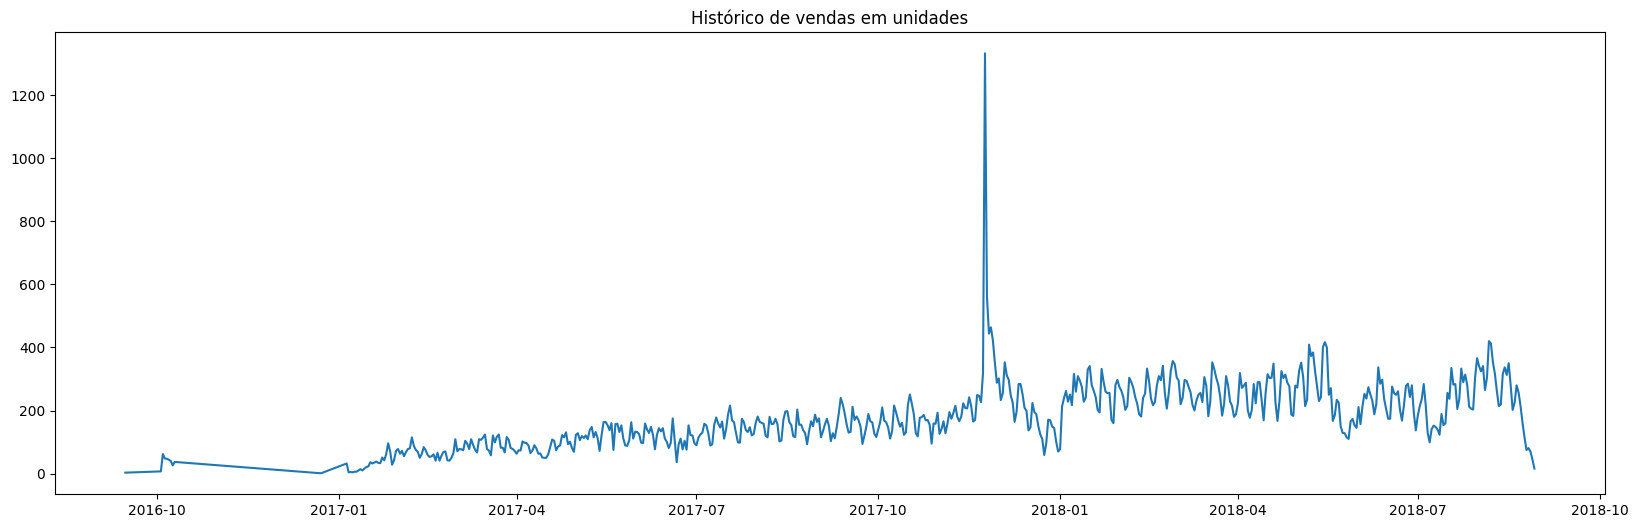

In [11]:
# Plotar resultados
fig, ax = plt.subplots(figsize = (20,6))

ax.plot(df_chart['sale_date'], df_chart['order_units'])
plt.title('Histórico de vendas em unidades')

plt.show()

In [12]:
# Avaliando o período de pico de vendas
df_chart.loc[df_chart['order_units'] > 400]

,sale_date,order_units
333,2017-11-24,1333
334,2017-11-25,561
335,2017-11-26,444
336,2017-11-27,464
337,2017-11-28,422
497,2018-05-07,409
504,2018-05-14,401
505,2018-05-15,417
588,2018-08-06,420
589,2018-08-07,413


- Os 6 maiores dias de vendas aconteceram na black fiday de 2017 (última sexta-feira do mês de novembro). Essa é uma data que se repete todo ano e, por isso, faz sentido manter esses registros, por mais que fujam muito do padrão.
- Na etapa de Feature Engineering, uma feature será adicionada para identificar esse evento.

In [13]:
# Visualizando a descrição estatística das colunas numéricas
with pd.option_context('display.float_format', "{:.2f}".format):
    display(df.describe())

,sale_date,product_description_lenght,order_units,unit_price,zip_code_prefix
count,98795,98795.00,98795.00,98795.00,98795.00
mean,2018-01-02 02:12:19.932182784,786.56,1.10,123.87,35127.43
min,2016-09-15 00:00:00,4.00,1.00,0.85,1003.00
25%,2017-09-14 00:00:00,348.00,1.00,40.00,11320.00
50%,2018-01-21 00:00:00,603.00,1.00,78.00,24416.00
75%,2018-05-06 00:00:00,986.00,1.00,139.00,58900.00
max,2018-08-29 00:00:00,3992.00,20.00,6735.00,99980.00
std,NaN,649.70,0.46,187.43,29820.77


- Avaliando o pairplot, temos que a coluna de product_description_lenght não tem correlação relevante com o número de unidades vendidas. Assim, essa coluna também será excluida.

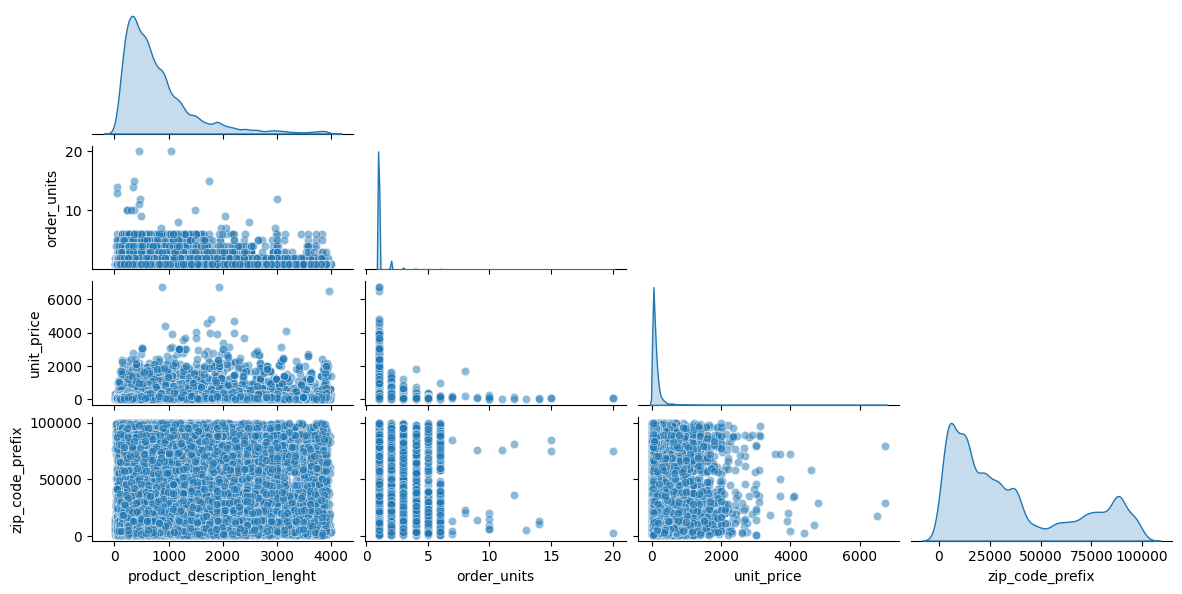

In [14]:
# Plotando um KDE correlacionando as variáveis numéricas
sns.pairplot(
    df,
    diag_kind = 'kde',
    plot_kws=dict(alpha=0.5),
    corner=True,
    palette='tab10',
    height=1.5,
    aspect=2
    );

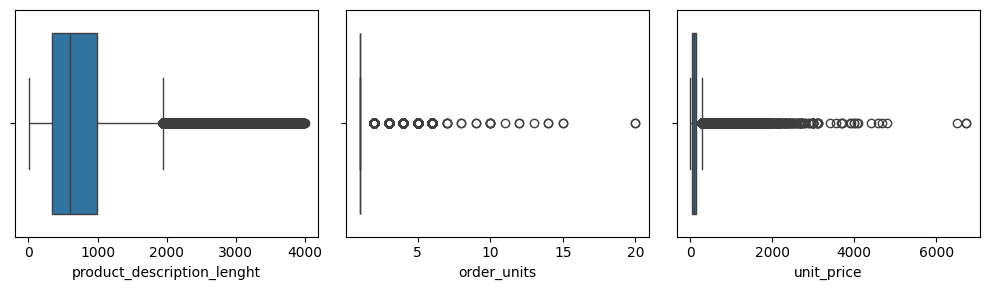

In [15]:
# Plotando os boxplots para avaliar a distribuição dos dados
fig, axs = plt.subplots(nrows = 1, ncols = 3, figsize = (10, 3), tight_layout = True)

for ax, col in zip(axs, df.select_dtypes('number')):
    sns.boxplot(data = df, x = col, ax=ax)

plt.show()

In [16]:
# Avaliando a cardinalidade das features
print('Cardinalidade das Features:')
df.nunique()

Cardinalidade das Features:


sale_date                       612
order_id                      95146
customer_id                   95146
product_id                    31632
product_category_name            73
product_description_lenght     2944
order_units                      16
unit_price                     5793
zip_code_prefix               14844
customer_state                   27
dtype: int64

- Avaliando a cardinalidade das colunas(número de valores distintos), temos que as colunas de order-id, customer_id, product_id são números de identificação específicos para cada pedido. Esse tipo de informação não agrega valor à análise e, por isso, as colunas serão desconsideradas.
- A coluna de Zip_code_prefix também será excluida para evitar duplicidade de informações, já que a região de venda é representada pela coluna customer_state.

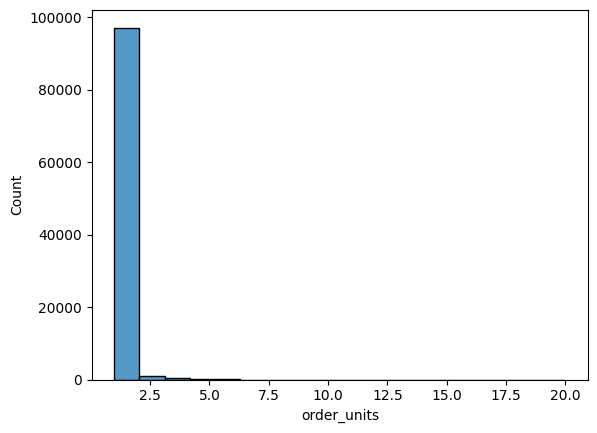

In [17]:
# Avaliando outliers de vendas em unidades com histograma
sns.histplot(df.order_units);

In [18]:
# Avaliando as vendas com 7 unidades ou mais
df.loc[df['order_units'] >= 7].sort_values('order_units', ascending = False)

,sale_date,order_id,customer_id,product_id,product_category_name,product_description_lenght,order_units,unit_price,zip_code_prefix,customer_state
94717,2017-08-23,ab14fdcfbe524636d65ee38360e22ce8,bd5d39761aa56689a265d95d8d32b8be,9571759451b1d780ee7c15012ea109d4,automotivo,1042.0,20,98.70,74825,GO
87576,2018-02-22,1b15974a0141d54e36626dca3fdc731a,be1b70680b9f9694d8c70f41fa3dc92b,ee3d532c8a438679776d222e997606b3,informatica_acessorios,452.0,20,100.00,3029,SP
30539,2017-11-23,428a2f660dc84138d969ccd69a0ab6d5,10de381f8a8d23fff822753305f71cae,89b190a046022486c635022524a974a8,moveis_decoracao,1744.0,15,65.49,84600,PR
66935,2017-01-30,9ef13efd6949e4573a18964dd1bbe7f5,adb32467ecc74b53576d9d13a5a55891,37eb69aca8718e843d897aa7b82f462d,ferramentas_jardim,369.0,15,51.00,74885,GO
27839,2018-02-21,9bdc4d4c71aa1de4606060929dee888c,a7693fba2ff9583c78751f2b66ecab9d,44a5d24dd383324a421569ca697b13c2,telefonia,55.0,14,29.99,13330,SP
27571,2017-12-13,73c8ab38f07dc94389065f7eba4f297a,d5f2b3f597c7ccafbb5cac0bcc3d6024,422879e10f46682990de24d770e7f83d,ferramentas_jardim,348.0,14,59.00,11065,SP
48279,2018-04-12,37ee401157a3a0b28c9c6d0ed8c3b24b,7d321bd4e8ba1caf74c4c1aabd9ae524,d34c07a2d817ac73f4caf8c574215fed,telefonia,56.0,13,29.99,5006,SP
8396,2018-01-11,3a213fcdfe7d98be74ea0dc05a8b31ae,91f92cfee46b79581b05aa974dd57ce5,a62e25e09e05e6faf31d90c6ec1aa3d1,relogios_presentes,3006.0,12,108.00,81280,PR
17127,2017-10-09,2c2a19b5703863c908512d135aa6accc,0d93f21f3e8543a9d0d8ece01561f5b2,03e1c946c0ddfc58724ff262aef08dff,utilidades_domesticas,465.0,12,20.70,36025,MG
91116,2018-07-25,6c355e2913545fa6f72c40cbca57729e,d95ca02ab50105ccce682bdf9ffdc3b4,32e18e89237933ebdaaebd78a27e7fa1,utilidades_domesticas,464.0,11,26.18,75905,GO


- De fato existem poucos registros de vendas de mais de uma unidade no mesmo pedido. Porém, esses dados serão mantidos, já que não existe um padrão claro para a venda de mais unidades de um produto por pedido e, ao que tudo indica, é apenas a representação da dinâmica de vendas de determinados produtos

In [19]:
# # Excluindo as colunas
df = df.drop(['order_id', 'customer_id', 'product_id', 'product_description_lenght', 'zip_code_prefix'], axis = 1)

In [20]:
# Salvando a nova base
df.to_csv(r'../data/sales_db_02.csv', index = False)

### Análise de Séries Temporais

- Como o objetivo do projeto é prever o total de unidades vendidas por dia, é necessário avaliar os dados também como uma série temporal, ou seja, uma única sequência contínua de vendas diárias.
- Nessa etapa são avaliados o período útil da série, a tendência, a sazonalidade e a estacionariedade. Essas análises embasam a escolha e a configuração dos modelos estatísticos (ARIMA e SARIMA) na etapa de modelagem.

In [21]:
# Criando a série temporal de vendas diárias
df_ts = df[['sale_date', 'order_units']].groupby('sale_date').sum()

# Preenchendo os dias sem vendas com zero para obter uma série contínua
df_ts = df_ts.asfreq('D', fill_value = 0)

# Visualizando as informações da série
print('Início da série: {}'.format(df_ts.index.min().date()))
print('Fim da série: {}'.format(df_ts.index.max().date()))
print('Número de dias: {}'.format(df_ts.shape[0]))
print('Dias sem vendas: {}'.format((df_ts['order_units'] == 0).sum()))

Início da série: 2016-09-15
Fim da série: 2018-08-29
Número de dias: 714
Dias sem vendas: 102


In [22]:
# Avaliando o total de vendas por mês no início da série
df_ts.resample('MS').sum().head(6)

,order_units
sale_date,
2016-09-01,3
2016-10-01,311
2016-11-01,0
2016-12-01,1
2017-01-01,901
2017-02-01,1802


In [23]:
# Avaliando os primeiros dias de vendas de 2017
df_ts.loc['2017-01-01':'2017-01-10'].T

sale_date,2017-01-01,2017-01-02,2017-01-03,2017-01-04,2017-01-05,2017-01-06,2017-01-07,2017-01-08,2017-01-09,2017-01-10
order_units,0,0,0,0,32,4,5,4,6,6


- Os registros de 2016 são esparsos: setembro tem apenas 3 unidades vendidas, outubro concentra as vendas em poucos dias, novembro não tem nenhuma venda e dezembro tem apenas um pedido. Esse período não representa a dinâmica normal de vendas da plataforma e deixaria uma lacuna de quase três meses na série.
- Em janeiro de 2017, os quatro primeiros dias também não têm vendas. As vendas passam a ser contínuas a partir de 05/01/2017, que será adotado como início da série.

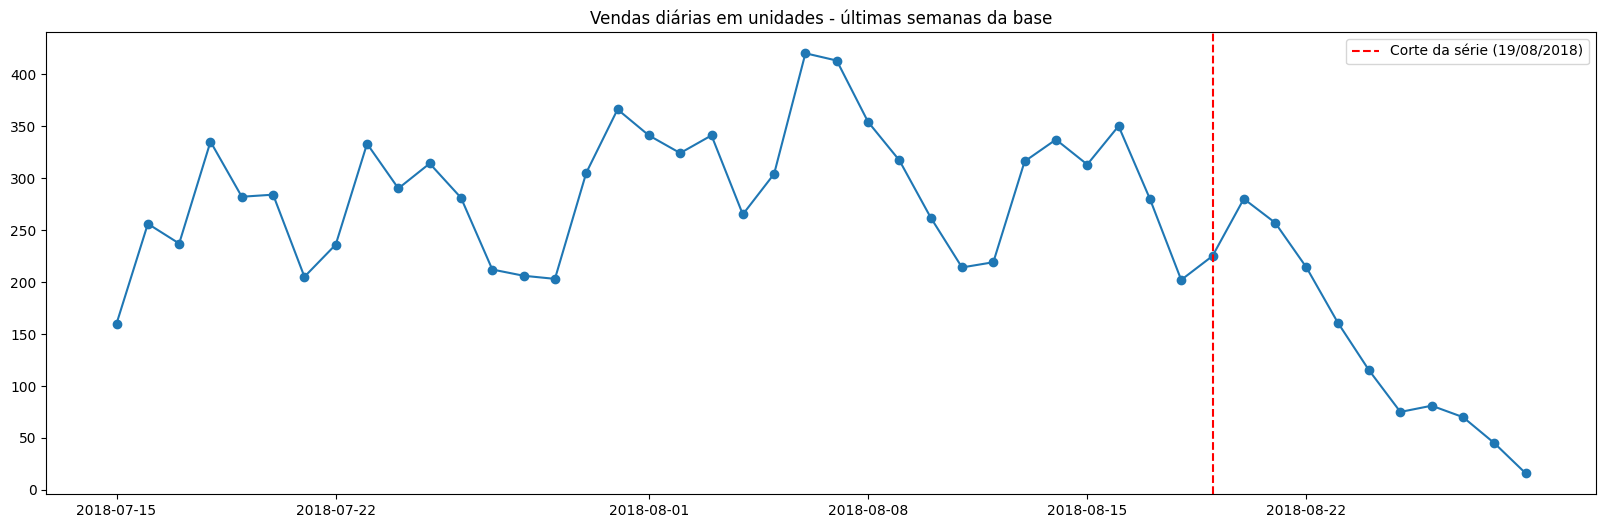

In [24]:
# Plotando as vendas diárias das últimas semanas da base
fig, ax = plt.subplots(figsize = (20,6))

ax.plot(df_ts.loc['2018-07-15':, 'order_units'], marker = 'o')
ax.axvline(pd.Timestamp('2018-08-19'), color = 'red', linestyle = '--', label = 'Corte da série (19/08/2018)')
plt.title('Vendas diárias em unidades - últimas semanas da base')
plt.legend()

plt.show()

- A partir de 21/08/2018 as vendas passam a cair dia após dia, saindo de 280 unidades em 20/08/2018 para apenas 16 unidades em 29/08/2018. Essa queda não representa um comportamento real de vendas: ela também aparece quando se consideram pedidos de todos os status (e não só os entregues), o que indica que a extração da base pela Olist foi feita no fim de agosto e os pedidos desses últimos dias estão incompletos.
- Para não ensinar aos modelos uma queda artificial, a série será cortada em 19/08/2018, um domingo, de forma que a última semana da série fique completa.

In [25]:
# Definindo o período útil da série
df_ts = df_ts.loc['2017-01-05':'2018-08-19']

# Visualizando as informações da série ajustada
print('Início da série: {}'.format(df_ts.index.min().date()))
print('Fim da série: {}'.format(df_ts.index.max().date()))
print('Número de dias: {}'.format(df_ts.shape[0]))
print('Dias sem vendas: {}'.format((df_ts['order_units'] == 0).sum()))

Início da série: 2017-01-05
Fim da série: 2018-08-19
Número de dias: 592
Dias sem vendas: 0


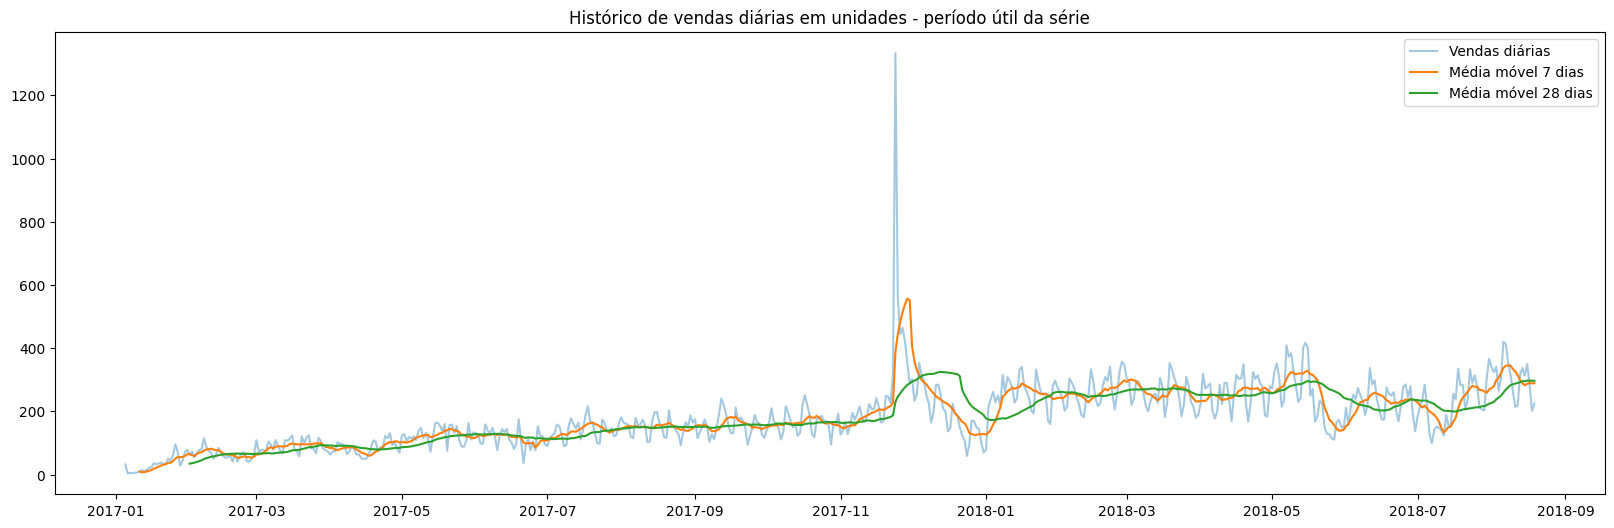

In [26]:
# Plotando a série com as médias móveis de 7 e 28 dias
fig, ax = plt.subplots(figsize = (20,6))

ax.plot(df_ts['order_units'], label = 'Vendas diárias', alpha = 0.4)
ax.plot(df_ts['order_units'].rolling(7).mean(), label = 'Média móvel 7 dias')
ax.plot(df_ts['order_units'].rolling(28).mean(), label = 'Média móvel 28 dias')
plt.title('Histórico de vendas diárias em unidades - período útil da série')
plt.legend()

plt.show()

- A série apresenta uma tendência de crescimento ao longo de 2017, que se estabiliza em 2018 em torno de 250 a 300 unidades por dia.
- A Black Friday de 2017 (24/11/2017) aparece como o maior pico da série, seguida de alguns dias ainda acima do padrão.
- Existem duas quedas pontuais relevantes: no fim de dezembro de 2017 (período de festas de fim de ano) e no fim de maio de 2018, que coincide com a greve dos caminhoneiros (21 a 31/05/2018). São eventos que também precisam ser considerados nos modelos.

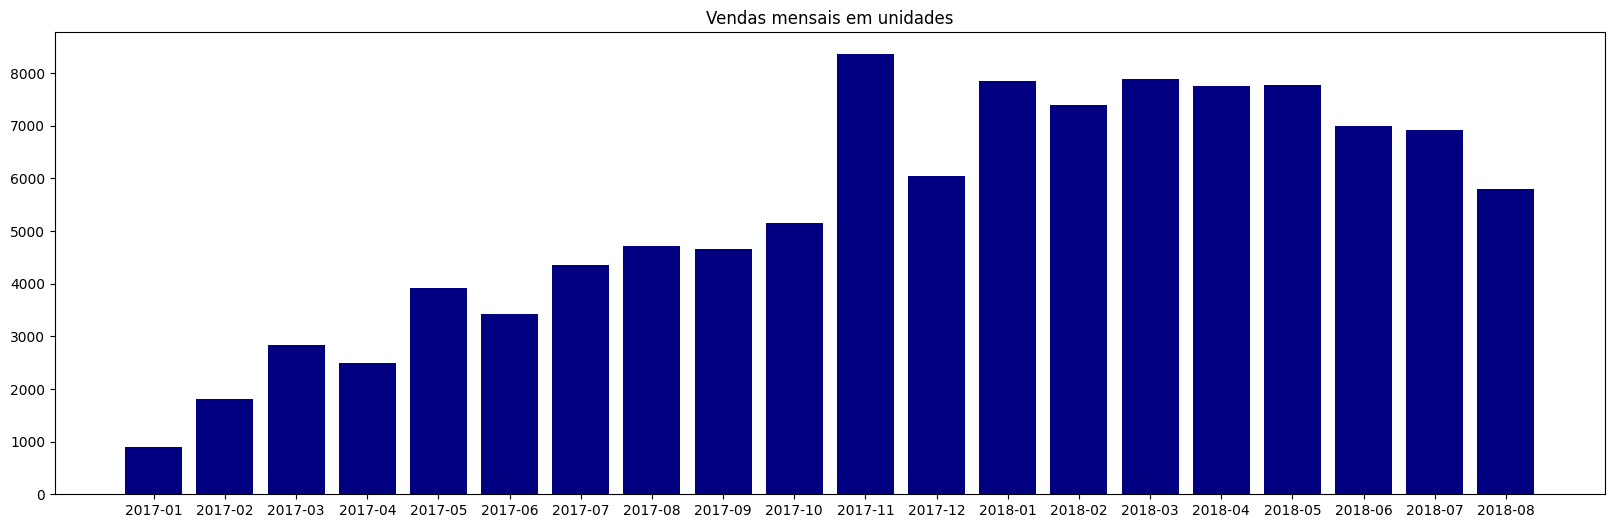

In [27]:
# Avaliando as vendas totais por mês
df_month = df_ts.resample('MS').sum()

# Plotando resultados
fig, ax = plt.subplots(figsize = (20,6))

ax.bar(df_month.index.strftime('%Y-%m'), df_month['order_units'], color = 'navy')
plt.title('Vendas mensais em unidades')

plt.show()

- Os meses de janeiro de 2017 e agosto de 2018 estão incompletos (a série começa em 05/01/2017 e termina em 19/08/2018), por isso aparecem mais baixos.
- A base tem pouco mais de 19 meses de histórico e apenas um mês de novembro. Assim, não é possível estimar uma sazonalidade anual: a Black Friday aparece uma única vez na série e deve ser tratada como um evento pontual (variável indicadora) e não como um padrão sazonal.

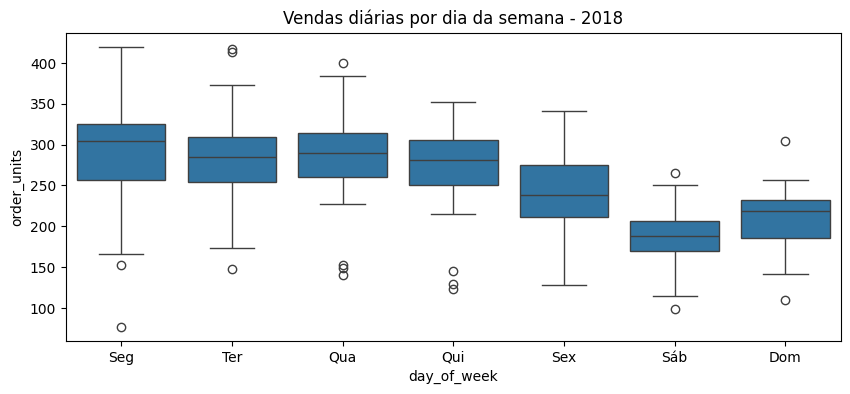

In [28]:
# Criando base para avaliar as vendas por dia da semana (somente 2018, período com nível de vendas estável)
df_dow = df_ts.loc['2018-01-01':].copy()
df_dow['day_of_week'] = df_dow.index.dayofweek

# Plotando os boxplots das vendas por dia da semana
fig, ax = plt.subplots(figsize = (10,4))

sns.boxplot(data = df_dow, x = 'day_of_week', y = 'order_units', ax = ax)
ax.set_xticks(range(7))
ax.set_xticklabels(['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom'])
plt.title('Vendas diárias por dia da semana - 2018')

plt.show()

In [29]:
# Avaliando a média de vendas por dia da semana
dow_mean = df_dow.groupby('day_of_week')['order_units'].mean()
dow_mean.index = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']
dow_mean.round(1)

Seg    289.9
Ter    285.7
Qua    284.7
Qui    270.4
Sex    237.3
Sáb    188.9
Dom    211.3
Name: order_units, dtype: float64

- Existe uma sazonalidade semanal clara: as vendas são maiores de segunda a quarta-feira, caem gradualmente até sexta e atingem o menor nível no sábado. Em 2018, a média do fim de semana ficou cerca de 27% abaixo da média dos dias úteis.
- Por isso, a sazonalidade a ser considerada nos modelos é a semanal, com período de 7 dias.

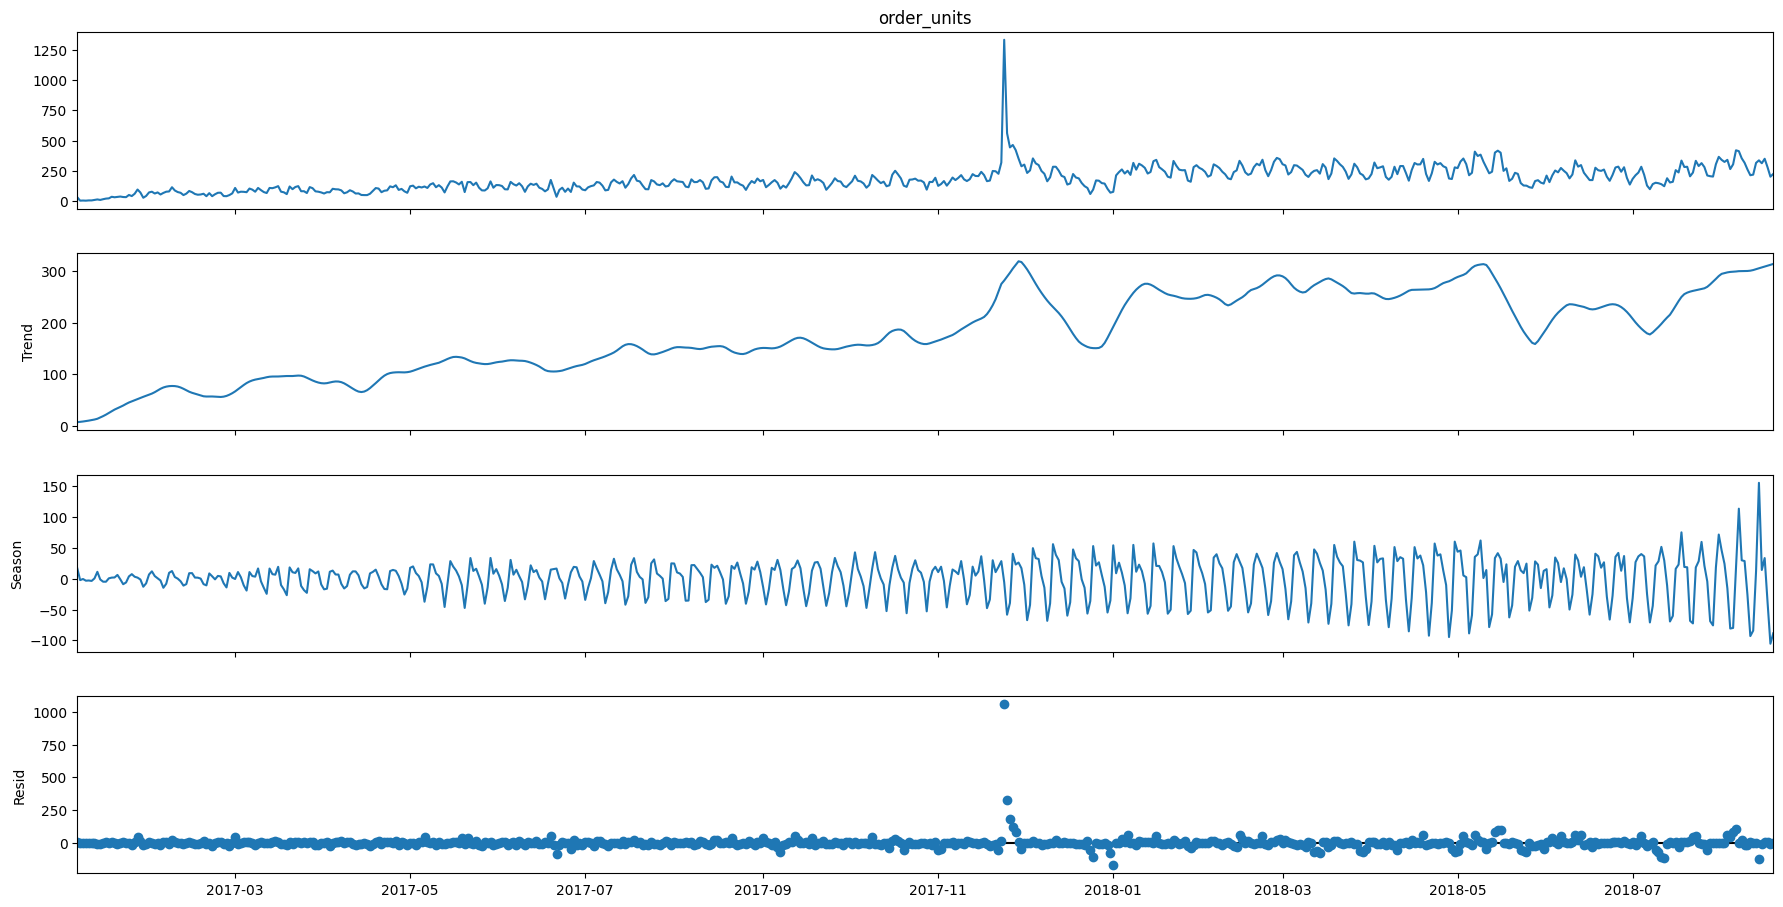

In [30]:
# Decompondo a série em tendência, sazonalidade e resíduo
stl = STL(df_ts['order_units'], period = 7, robust = True).fit()

# Plotando resultados
fig = stl.plot()
fig.set_size_inches(20, 10)

plt.show()

In [31]:
# Calculando a força da tendência e da sazonalidade (escala de 0 a 1)
var_resid = stl.resid.var()
forca_tendencia = max(0, 1 - var_resid / (stl.trend + stl.resid).var())
forca_sazonalidade = max(0, 1 - var_resid / (stl.seasonal + stl.resid).var())

print('Força da tendência: {:.2f}'.format(forca_tendencia))
print('Força da sazonalidade semanal: {:.2f}'.format(forca_sazonalidade))

Força da tendência: 0.71
Força da sazonalidade semanal: 0.23


- A decomposição STL separa a série em tendência, sazonalidade semanal e resíduo. A versão robusta foi utilizada para que o pico da Black Friday não distorça a tendência e a sazonalidade; esse pico fica concentrado no resíduo.
- A força da tendência é alta (0,71), enquanto a força da sazonalidade semanal é moderada (0,23). Ou seja, o padrão semanal existe, mas boa parte da variação diária é ruído. É esperado, portanto, que os erros de previsão no nível diário sejam relevantes e que a precisão melhore quando as previsões forem agregadas por semana ou mês.
- A amplitude da sazonalidade cresce junto com o nível da série: no início de 2017 a variação semanal é de poucas unidades e, em 2018, chega a cerca de 100 unidades. Isso indica uma sazonalidade multiplicativa, e aplicar o logaritmo nas vendas antes da modelagem pode estabilizar essa variação. Essa transformação será testada na etapa de modelagem.

- Para avaliar a estacionariedade da série, serão utilizados dois testes complementares:
  - **ADF (Augmented Dickey-Fuller)**: a hipótese nula é de que a série **não** é estacionária. Um p-valor abaixo de 0,05 indica que a série é estacionária.
  - **KPSS**: a hipótese nula é de que a série **é** estacionária. Um p-valor abaixo de 0,05 indica que a série não é estacionária.
- A série é avaliada no nível original e após as diferenciações simples (lag 1) e sazonal (lag 7), que são as transformações aplicadas pelos modelos ARIMA e SARIMA.

In [32]:
# Definindo função para os testes de estacionariedade
def testes_estacionariedade(serie, nome):
    adf_p = adfuller(serie, autolag = 'AIC')[1]
    kpss_p = kpss(serie, regression = 'c', nlags = 'auto')[1]
    print('{}: ADF p-valor = {:.4f} | KPSS p-valor = {:.4f}'.format(nome, adf_p, kpss_p))

# Aplicando os testes na série original e nas séries diferenciadas
serie = df_ts['order_units']

testes_estacionariedade(serie, 'Série original')
testes_estacionariedade(serie.diff().dropna(), 'Diferença simples (lag 1)')
testes_estacionariedade(serie.diff(7).dropna(), 'Diferença sazonal (lag 7)')
testes_estacionariedade(serie.diff().diff(7).dropna(), 'Diferença simples + sazonal')

Série original: ADF p-valor = 0.0666 | KPSS p-valor = 0.0100
Diferença simples (lag 1): ADF p-valor = 0.0000 | KPSS p-valor = 0.1000
Diferença sazonal (lag 7): ADF p-valor = 0.0000 | KPSS p-valor = 0.1000
Diferença simples + sazonal: ADF p-valor = 0.0000 | KPSS p-valor = 0.1000


- Na série original, o ADF não rejeita a hipótese de não estacionariedade (p-valor de 0,07) e o KPSS rejeita a hipótese de estacionariedade (p-valor de 0,01, que é o limite inferior da tabela do teste, ou seja, o p-valor real é ainda menor). Os dois testes concordam: a série original não é estacionária, o que é coerente com a tendência observada.
- Após uma diferenciação, simples ou sazonal, os dois testes passam a indicar estacionariedade. O KPSS retorna 0,10 porque esse é o limite superior da tabela de p-valores do teste, ou seja, o p-valor real é maior que 0,10. Portanto, uma diferenciação (d = 1 e/ou D = 1) é suficiente para os modelos ARIMA e SARIMA.

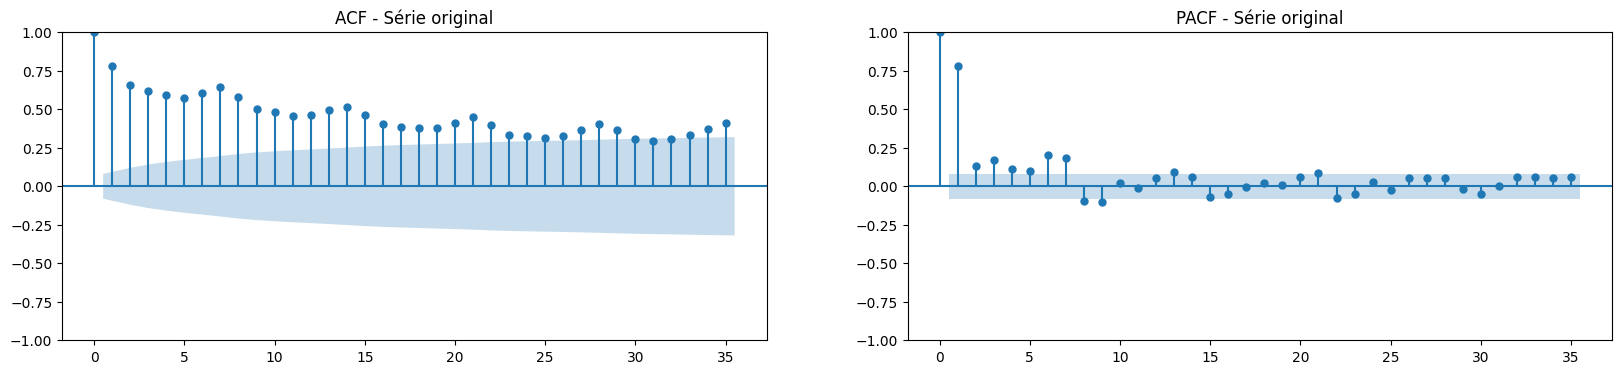

In [33]:
# Plotando a autocorrelação (ACF) e a autocorrelação parcial (PACF) da série original
fig, axs = plt.subplots(nrows = 1, ncols = 2, figsize = (20, 4))

plot_acf(serie, lags = 35, ax = axs[0])
plot_pacf(serie, lags = 35, ax = axs[1])
axs[0].set_title('ACF - Série original')
axs[1].set_title('PACF - Série original')

plt.show()

- Na série original, a ACF decai lentamente e apresenta picos nos lags 7, 14, 21 e 28. Esse comportamento confirma a presença de tendência (decaimento lento) e de sazonalidade semanal (picos a cada 7 dias).

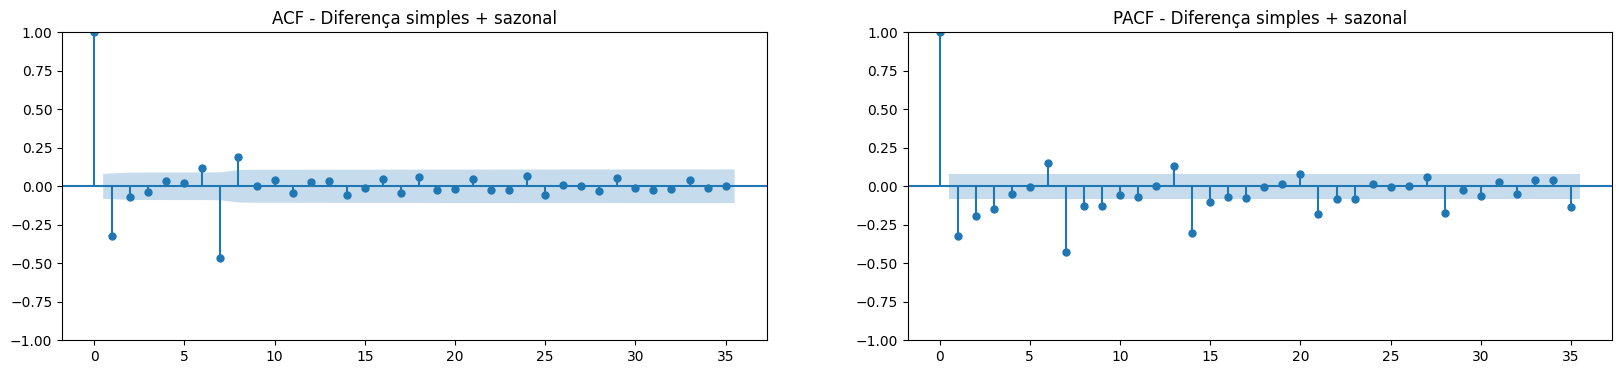

In [34]:
# Plotando a ACF e a PACF da série com diferença simples e sazonal
serie_diff = serie.diff().diff(7).dropna()

fig, axs = plt.subplots(nrows = 1, ncols = 2, figsize = (20, 4))

plot_acf(serie_diff, lags = 35, ax = axs[0])
plot_pacf(serie_diff, lags = 35, ax = axs[1])
axs[0].set_title('ACF - Diferença simples + sazonal')
axs[1].set_title('PACF - Diferença simples + sazonal')

plt.show()

- Após as diferenciações, a ACF apresenta autocorrelação negativa significativa no lag 1 (cerca de -0,32) e no lag 7 (cerca de -0,46), e fica próxima de zero nos demais lags, exceto por pequenas autocorrelações positivas nos lags 6 e 8. Já a PACF decai de forma gradual após o lag 1 e também nos lags sazonais (7, 14, 21 e 28).
- Esse padrão (ACF com corte e PACF com decaimento) indica um componente de médias móveis simples de ordem 1 e um componente de médias móveis sazonal de ordem 1. As pequenas autocorrelações nos lags 6 e 8 são justamente as esperadas pela interação entre esses dois componentes. Assim, um ponto de partida para o SARIMA é o modelo **SARIMA(0,1,1)(0,1,1)7**. As ordens finais serão definidas na etapa de modelagem, comparando diferentes configurações pelo critério de informação (AIC) e pelo erro de validação.

In [35]:
# Salvando a série temporal para a etapa de modelagem
df_ts.to_csv(r'../data/sales_ts_daily.csv')

### Conclusões da análise de séries temporais

- **Período útil**: a série será modelada de 05/01/2017 a 19/08/2018. Os dados de 2016 são esparsos e os últimos dias de agosto de 2018 estão incompletos na base.
- **Tendência**: crescimento ao longo de 2017 e estabilização em 2018. A série original não é estacionária, e uma diferenciação é suficiente para torná-la estacionária.
- **Sazonalidade**: semanal (período de 7 dias), com vendas maiores no início da semana e menores aos sábados. Não há histórico suficiente para estimar sazonalidade anual.
- **Eventos**: a Black Friday aparece uma única vez e deve entrar nos modelos como variável indicadora, assim como o período de festas de fim de ano, os feriados nacionais e a greve dos caminhoneiros de maio de 2018.
- **Transformação**: a amplitude da sazonalidade cresce com o nível da série, por isso a transformação logarítmica das vendas será testada na modelagem.
- **Modelos**: os resultados indicam SARIMA com período sazonal de 7 dias, partindo de SARIMA(0,1,1)(0,1,1)7. Para os modelos de machine learning, as features devem incluir o dia da semana, defasagens (lags) e médias móveis calculadas somente com dados passados.